## Mini-Project : Data Analysis for Marketing Strategy



### Task

1. Which states have the most sales?
2. What is the difference between New York and California in terms of sales and profit? (Compare the total sales and profit between New York and California.)
3. Who is an outstanding customer in New York?
4. Are there any differences among states in profitability?
5. The Pareto Principle, also known as the 80/20 rule, is a concept derived from the work of Italian economist Vilfredo Pareto. It states that roughly 80% of the effects come from 20% of the causes. For instance, identifying the top 20% of products that generate 80% of sales or the top 20% of customers that contribute to 80% of profit can help in prioritizing efforts and resources. This focus can lead to improved efficiency and effectiveness in business strategies. Can we apply Pareto principle to customers and Profit ? (Determine if 20% of the customers contribute to 80% of the profit.)
6. What are the Top 20 cities by Sales ? What about the Top 20 cities by Profit ? Are there any difference among cities in profitability ? (Identify the top 20 cities based on total sales and total profit and analyze differences in profitability among these cities.)
7. What are the Top 20 customers by Sales?
8. Plot the Cumulative curve in Sales by Customers. Can we apply Pareto principle to customers and Sales ?
9. Based on the analysis, make decisions on which states and cities to prioritize for marketing strategies.


In [1]:
import pandas as pd

In [27]:
import matplotlib.pyplot as plt

In [99]:
import numpy as np

In [11]:
%pip install xlrd

Note: you may need to restart the kernel to use updated packages.


In [12]:
df=pd.read_excel("US Superstore data.xls")

df.head()

/var/folders/0w/zzz81vx51yv5qbm4h4npjpcm0000gn/T/ipykernel_78587/1091401043.py:1: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df=pd.read_excel("US Superstore data.xls")


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [13]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.isna().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [14]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355,2016-05-03 23:06:58.571142,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108


### 1. Which states have the most sales?


In [26]:
state_sales=df.groupby("State")["Sales"].sum().sort_values(ascending=False)

<function matplotlib.pyplot.show(close=None, block=None)>

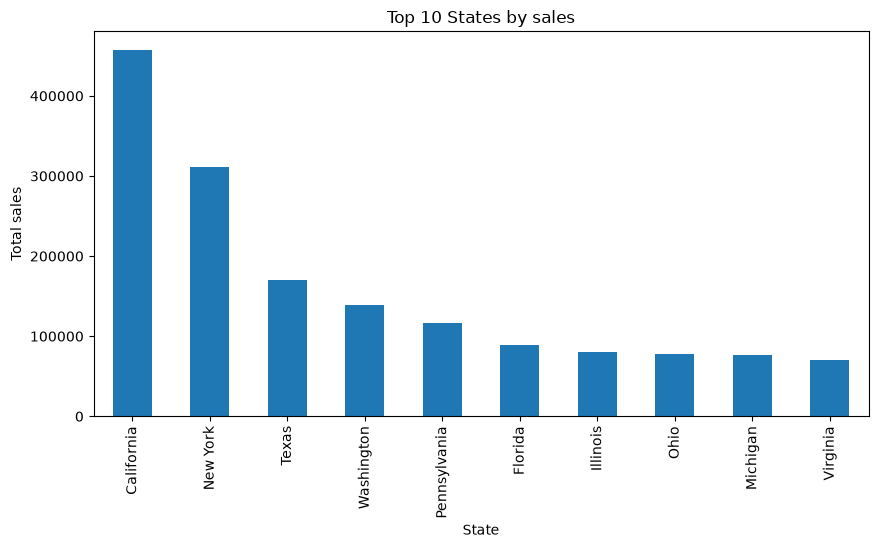

In [29]:
state_sales.head(10).plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Top 10 States by sales")
plt.xlabel("State")
plt.ylabel("Total sales")
plt.show

Conclusion:

California has the highest total sales, followed by New York and Texas.

### 2. What is the difference between New York and California in terms of sales and profit? (Compare the total sales and profit between New York and California.)


In [31]:
state_profit=df.groupby("State")["Profit"].sum().sort_values(ascending=False)

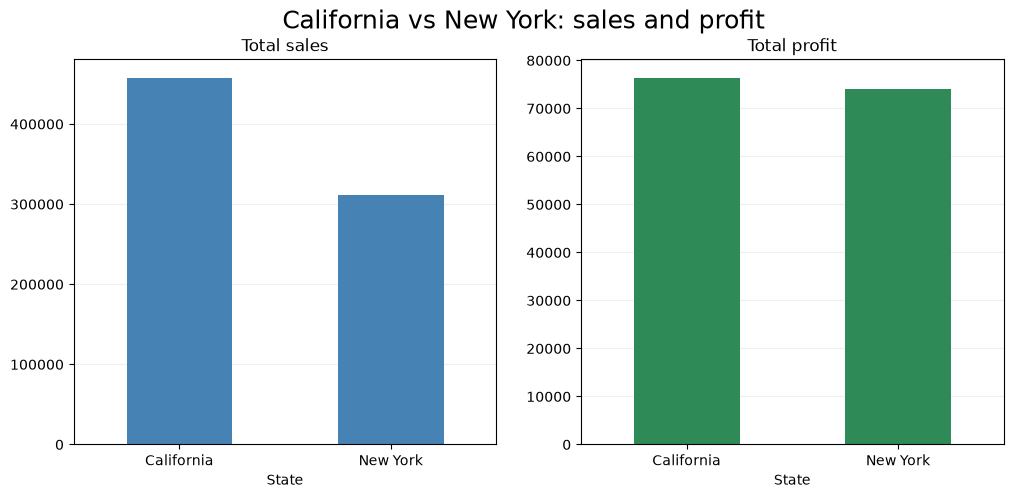

In [52]:
fig, axes=plt.subplots(1,2,figsize=(12,5))

state_sales.loc[["California", "New York"]].plot(
    kind="bar",
    ax=axes[0],
    color="steelblue"
    )
state_profit.loc[["California", "New York"]].plot(
    kind="bar",
    ax=axes[1],
    color="seagreen"
    )

axes[0].tick_params(axis="x", rotation=0)
axes[1].tick_params(axis="x", rotation=0)

axes[0].grid(axis="y", alpha=0.2)
axes[1].grid(axis="y", alpha=0.2)

axes[0].set_axisbelow(True)
axes[1].set_axisbelow(True)

fig.suptitle("California vs New York: sales and profit",fontsize=18)
axes[0].set_title("Total sales")
axes[1].set_title("Total profit")

plt.show()

Conclusion: According to the charts, California has much higher sales than New York, but their total profit is almost the same. This means New York has a higher profit margin and could be a better option for future marketing investments.

### 3. Who is an outstanding customer in New York?


In [53]:
df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False)

Customer Name
Sean Miller        25043.050
Tamara Chand       19052.218
Raymond Buch       15117.339
Tom Ashbrook       14595.620
Adrian Barton      14473.571
                     ...    
Roy Skaria            22.328
Mitch Gastineau       16.739
Carl Jackson          16.520
Lela Donovan           5.304
Thais Sissman          4.833
Name: Sales, Length: 793, dtype: float64

In [67]:
ny_df=df[df["State"]=="New York"]

ny_customers=ny_df.groupby("Customer ID").agg(  
    customer_name=("Customer Name","first"),
    sum_sales=("Sales","sum"),
    sum_profit=("Profit","sum"),
    total_orders=("Order ID","nunique")
)
ny_customers.head(10)

,customer_name,sum_sales,sum_profit,total_orders
Customer ID,,,,
AA-10315,Alex Avila,29.500,13.2826,1
AA-10375,Allen Armold,149.872,42.3643,1
AB-10060,Adam Bellavance,4438.686,1453.4346,1
AB-10105,Adrian Barton,117.960,5.8980,1
AB-10150,Aimee Bixby,797.522,300.7329,2
AB-10255,Alejandro Ballentine,37.940,18.2112,1
AC-10450,Amy Cox,70.212,25.7148,1
AC-10615,Ann Chong,2293.798,304.6453,2
AD-10180,Alan Dominguez,179.440,74.9920,2


In [68]:
ny_customers.sort_values(["sum_sales"],ascending=False).head(10)

,customer_name,sum_sales,sum_profit,total_orders
Customer ID,,,,
TA-21385,Tom Ashbrook,13723.498,4599.2073,2
PF-19120,Peter Fuller,7678.228,543.2819,1
SV-20365,Seth Vernon,7359.918,1571.7964,1
TB-21400,Tom Boeckenhauer,6999.960,2239.9872,1
GT-14710,Greg Tran,6712.744,774.7935,4
TS-21370,Todd Sumrall,6492.314,1574.9714,2
KD-16270,Karen Daniels,6241.282,2283.0463,2
KD-16495,Keith Dawkins,5854.194,2510.8903,2
LW-17215,Luke Weiss,5048.186,773.1004,3


In [69]:
ny_customers.sort_values(["sum_profit"],ascending=False).head(10)

,customer_name,sum_sales,sum_profit,total_orders
Customer ID,,,,
TA-21385,Tom Ashbrook,13723.498,4599.2073,2
KD-16495,Keith Dawkins,5854.194,2510.8903,2
KD-16270,Karen Daniels,6241.282,2283.0463,2
NM-18445,Nathan Mautz,4821.292,2247.1904,2
TB-21400,Tom Boeckenhauer,6999.960,2239.9872,1
SR-20740,Steven Roelle,3904.680,1863.9614,3
PK-19075,Pete Kriz,4816.690,1695.3209,2
DM-13015,Darrin Martin,4283.792,1599.6806,1
TS-21370,Todd Sumrall,6492.314,1574.9714,2


In [70]:
ny_customers.sort_values(["total_orders"],ascending=False).head(10)

,customer_name,sum_sales,sum_profit,total_orders
Customer ID,,,,
PW-19030,Pauline Webber,1589.102,421.4954,4
GT-14710,Greg Tran,6712.744,774.7935,4
EH-13765,Edward Hooks,1887.906,585.3456,4
SH-20395,Shahid Hopkins,238.340,83.4807,4
SM-20950,Suzanne McNair,1625.236,415.0060,3
SR-20740,Steven Roelle,3904.680,1863.9614,3
MM-18280,Muhammed MacIntyre,84.380,33.3634,3
DR-12880,Dan Reichenbach,1197.020,496.8259,3
JG-15160,James Galang,1750.398,499.6413,3


In [73]:
top_customer = ny_customers.sort_values("sum_profit", ascending=False).iloc[0]

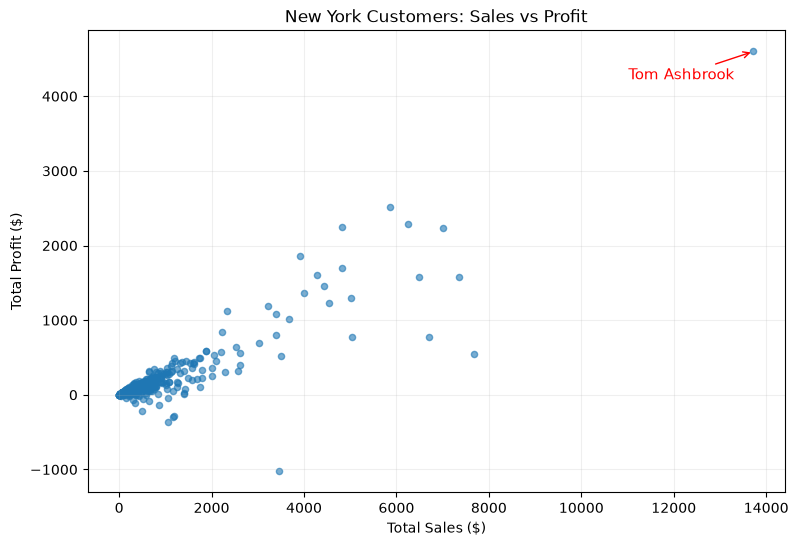

In [74]:
ny_customers.plot(
    kind="scatter",
    x="sum_sales",
    y="sum_profit",
    figsize=(9, 6),
    alpha=0.6
)

plt.annotate(
    top_customer["customer_name"],
    xy=(top_customer["sum_sales"], top_customer["sum_profit"]),
    xytext=(-90, -20),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "red"},
    fontsize=11,
    color="red"
)

plt.title("New York Customers: Sales vs Profit")
plt.xlabel("Total Sales ($)")
plt.ylabel("Total Profit ($)")
plt.grid(alpha=0.2)
plt.show()

Conclusion: According to the analysis, Tom Ashbrook is the outstanding customer in New York, with approximately $13,700 in sales and $4,600 in profit. He stands out from other customers in both sales and profitability.

### 4. Are there any differences among states in profitability?

In [85]:
df_states=df.groupby("State").agg(
    sum_sales=("Sales","sum"),
    sum_profit=("Profit","sum")
)
df_states["margin"]=df_states["sum_profit"]/df_states["sum_sales"]
df_states.head()

,sum_sales,sum_profit,margin
State,,,
Alabama,19510.6400,5786.8253,0.296598
Arizona,35282.0010,-3427.9246,-0.097158
Arkansas,11678.1300,4008.6871,0.343264
California,457687.6315,76381.3871,0.166885
Colorado,32108.1180,-6527.8579,-0.203309


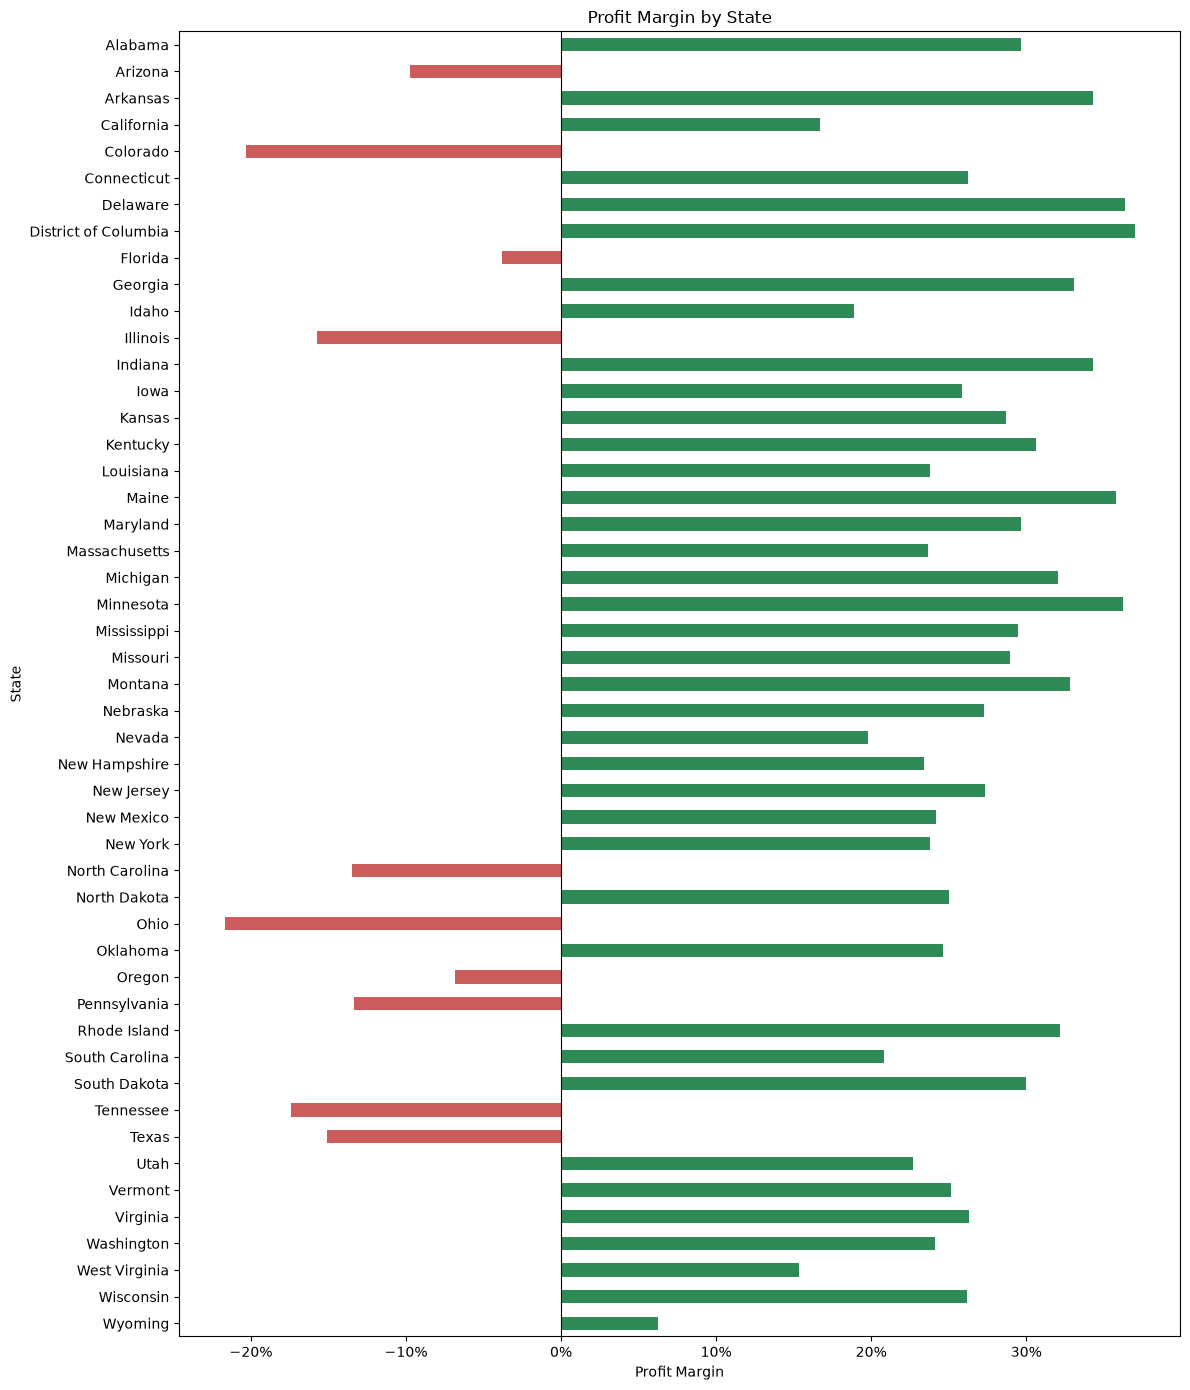

In [89]:
ax = df_states["margin"].plot(
    kind="barh",
    figsize=(12, 14),
    color=["seagreen" if x >= 0 else "indianred" for x in df_states["margin"]]
)
ax.invert_yaxis()

from matplotlib.ticker import PercentFormatter
ax.xaxis.set_major_formatter(PercentFormatter(1.0))

ax.axvline(x=0, color="black", linewidth=0.8)
ax.set_title("Profit Margin by State")
ax.set_xlabel("Profit Margin")
ax.set_ylabel("State")

plt.tight_layout()
plt.show()

Conclusion: Profit margins vary significantly across states. Some states have margins above 30%, while others, such as Texas, Ohio and Illinois, have negative margins. This shows that high sales do not always mean high profitability, as Texas.

### 5. The Pareto Principle, also known as the 80/20 rule, is a concept derived from the work of Italian economist Vilfredo Pareto. It states that roughly 80% of the effects come from 20% of the causes. For instance, identifying the top 20% of products that generate 80% of sales or the top 20% of customers that contribute to 80% of profit can help in prioritizing efforts and resources. This focus can lead to improved efficiency and effectiveness in business strategies. Can we apply Pareto principle to customers and Profit ? (Determine if 20% of the customers contribute to 80% of the profit.)


In [145]:
df_customers=df.groupby("Customer ID").agg(  
    customer_name=("Customer Name","first"),
    sum_profit=("Profit","sum"),
    sum_sales=("Sales","sum")
).sort_values("sum_profit",ascending=False)
df_customers.head(10)

,customer_name,sum_profit,sum_sales
Customer ID,,,
TC-20980,Tamara Chand,8981.3239,19052.218
RB-19360,Raymond Buch,6976.0959,15117.339
SC-20095,Sanjit Chand,5757.4119,14142.334
HL-15040,Hunter Lopez,5622.4292,12873.298
AB-10105,Adrian Barton,5444.8055,14473.571
TA-21385,Tom Ashbrook,4703.7883,14595.620
CM-12385,Christopher Martinez,3899.8904,8954.020
KD-16495,Keith Dawkins,3038.6254,8181.256
AR-10540,Andy Reiter,2884.6208,6608.448


In [147]:
import math

total_customers = len(df_customers)
top_20_count = round(total_customers * 0.2)
top_20_customers=df_customers.iloc[:top_20_count]

top_20_customers.info()

<class 'pandas.DataFrame'>
Index: 159 entries, TC-20980 to JG-15115
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_name    159 non-null    str    
 1   sum_profit       159 non-null    float64
 2   sum_sales        159 non-null    float64
 3   customer_number  159 non-null    int64  
 4   customer_share   159 non-null    float64
dtypes: float64(3), int64(1), str(1)
memory usage: 7.5+ KB


In [148]:
parreto_check=top_20_customers["sum_profit"].sum()/df_customers["sum_profit"].sum()

display(parreto_check)

np.float64(0.8166477099227463)

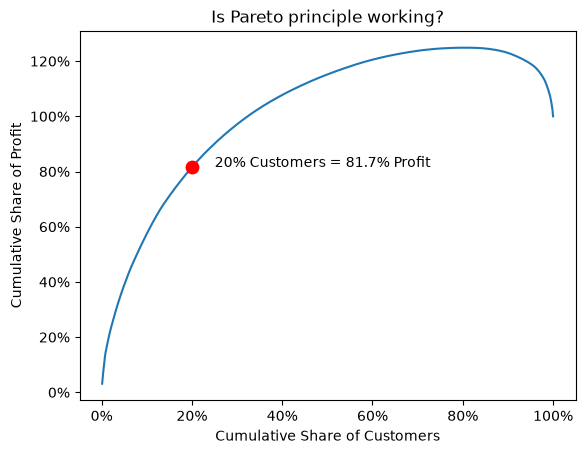

In [146]:
cumulative_profit_share=df_customers["sum_profit"].cumsum()/df_customers["sum_profit"].sum()
df_customers["customer_number"]=range(1,len(df_customers)+1)
df_customers["customer_share"]=df_customers["customer_number"]/len(df_customers)

plt.plot(df_customers["customer_share"], cumulative_profit_share)
plt.title("Is Pareto principle working?")
plt.xlabel("Cumulative Share of Customers")
plt.ylabel("Cumulative Share of Profit")

from matplotlib.ticker import PercentFormatter

ax = plt.gca()

ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

x_20=top_20_count/len(df_customers)
y_20=parreto_check

plt.scatter(x_20,y_20,color="red",s=80,zorder=5)
plt.text(x_20 + 0.05, y_20, f"20% Customers = {y_20:.1%} Profit")

plt.show()


Conclusion: According to mathemathics and graphic, we definetely can apply Pareto principle to customers and Profit and confirming that it is working.

### 6. What are the Top 20 cities by Sales ? What about the Top 20 cities by Profit ? Are there any difference among cities in profitability ? (Identify the top 20 cities based on total sales and total profit and analyze differences in profitability among these cities.)


In [132]:
df_cities=df.groupby(["State","City"]).agg(
    sum_sales=("Sales","sum"),
    sum_profit=("Profit","sum")
)
df_cities.head()

sum_sales  sum_profit
State   City                             
Alabama Auburn        1766.83    452.6071
        Decatur       3374.82   1000.0881
        Florence      1997.35    248.6589
        Hoover         525.85     18.7173
        Huntsville    2484.37   1005.2572

In [142]:
df_cities_sales=df_cities.sort_values("sum_sales",ascending=False).head(20)

display(df_cities_sum)

,,sum_sales,sum_profit
State,City,,
New York,New York City,256368.1610,62036.9837
California,Los Angeles,175851.3410,30440.7579
Washington,Seattle,119540.7420,29156.0967
California,San Francisco,112669.0920,17507.3854
Pennsylvania,Philadelphia,109077.0130,-13837.7674
Texas,Houston,64504.7604,-10153.5485
Illinois,Chicago,48539.5410,-6654.5688
California,San Diego,47521.0290,6377.1960
Michigan,Detroit,42446.9440,13181.7908


In [139]:
df_cities_profit=df_cities.sort_values("sum_profit",ascending=False).head(20)

display(df_cities_profit)

,,sum_sales,sum_profit
State,City,,
New York,New York City,256368.161,62036.9837
California,Los Angeles,175851.341,30440.7579
Washington,Seattle,119540.742,29156.0967
California,San Francisco,112669.092,17507.3854
Michigan,Detroit,42446.944,13181.7908
Indiana,Lafayette,19630.450,8976.0973
Delaware,Newark,20448.050,8086.1715
Georgia,Atlanta,17197.840,6993.6629
Minnesota,Minneapolis,16870.540,6824.5846


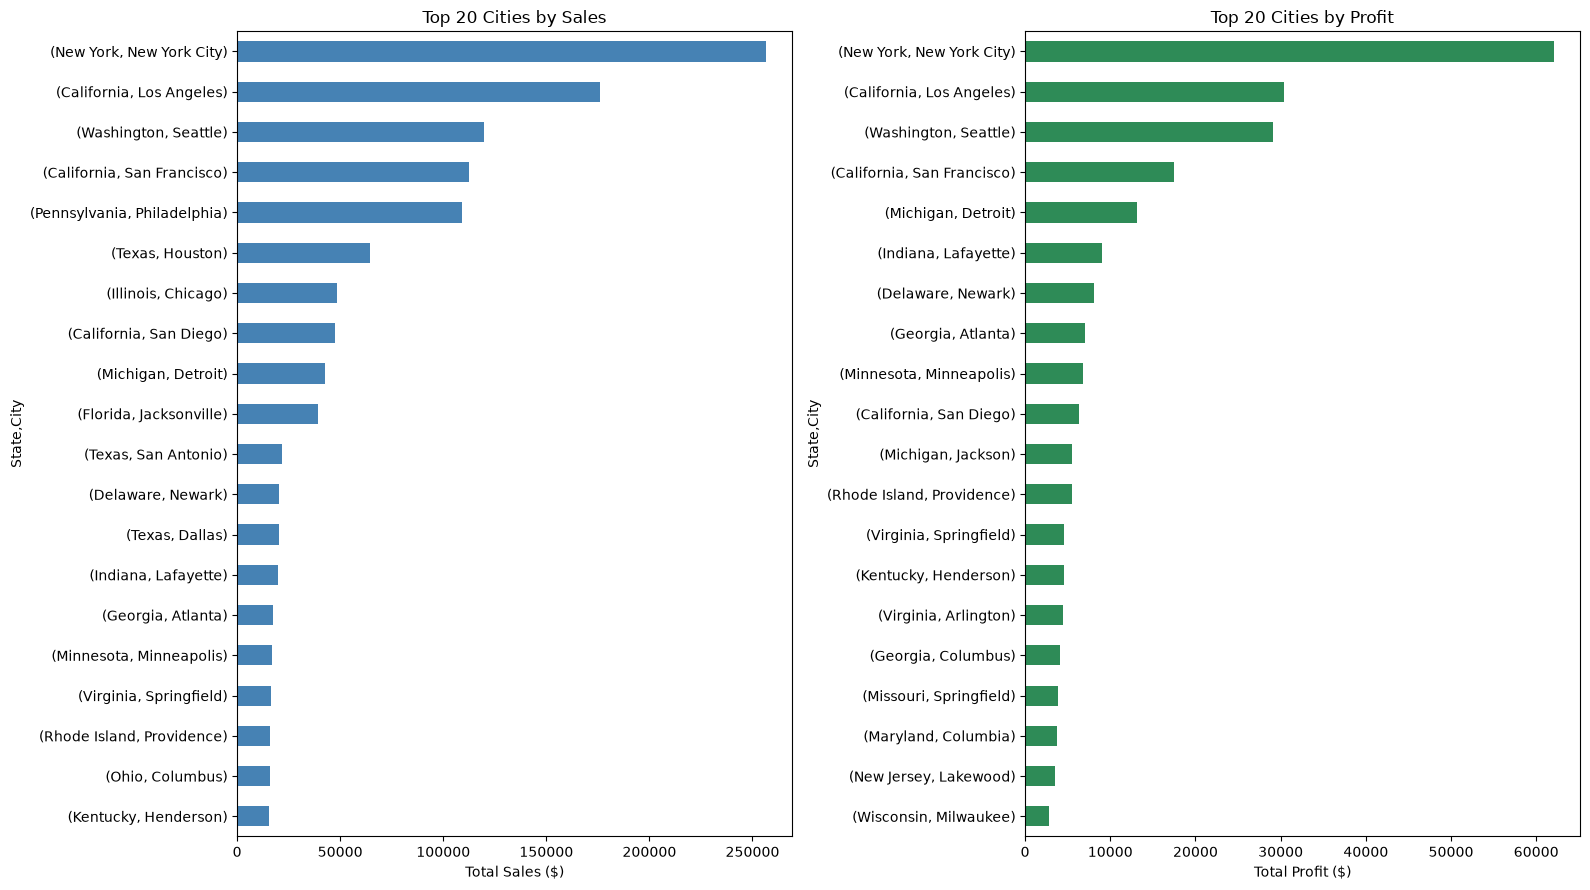

In [143]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9))

df_cities_sales["sum_sales"].plot(
    kind="barh", ax=axes[0], color="steelblue"
)

df_cities_profit["sum_profit"].plot(
    kind="barh", ax=axes[1], color="seagreen"
)

axes[0].set_title("Top 20 Cities by Sales")
axes[1].set_title("Top 20 Cities by Profit")

axes[0].set_xlabel("Total Sales ($)")
axes[1].set_xlabel("Total Profit ($)")

axes[0].invert_yaxis()
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

Conclusion: New York City has the highest sales and profit among all cities, followed by Los Angeles and Seattle. However, some cities with high sales, such as Philadelphia and Houston, are not among the most profitable. This shows that high sales do not always mean high profit.

### 7. What are the Top 20 customers by Sales?


In [154]:
top_20_sales=df_customers.sort_values("sum_sales",ascending=False).head(20)

display(top_20_sales)


,customer_name,sum_profit,sum_sales,customer_number,customer_share
Customer ID,,,,,
SM-20320,Sean Miller,-1980.7393,25043.050,786,0.991173
TC-20980,Tamara Chand,8981.3239,19052.218,1,0.001261
RB-19360,Raymond Buch,6976.0959,15117.339,2,0.002522
TA-21385,Tom Ashbrook,4703.7883,14595.620,6,0.007566
AB-10105,Adrian Barton,5444.8055,14473.571,5,0.006305
KL-16645,Ken Lonsdale,806.8550,14175.229,123,0.155107
SC-20095,Sanjit Chand,5757.4119,14142.334,3,0.003783
HL-15040,Hunter Lopez,5622.4292,12873.298,4,0.005044
SE-20110,Sanjit Engle,2650.6769,12209.438,13,0.016393


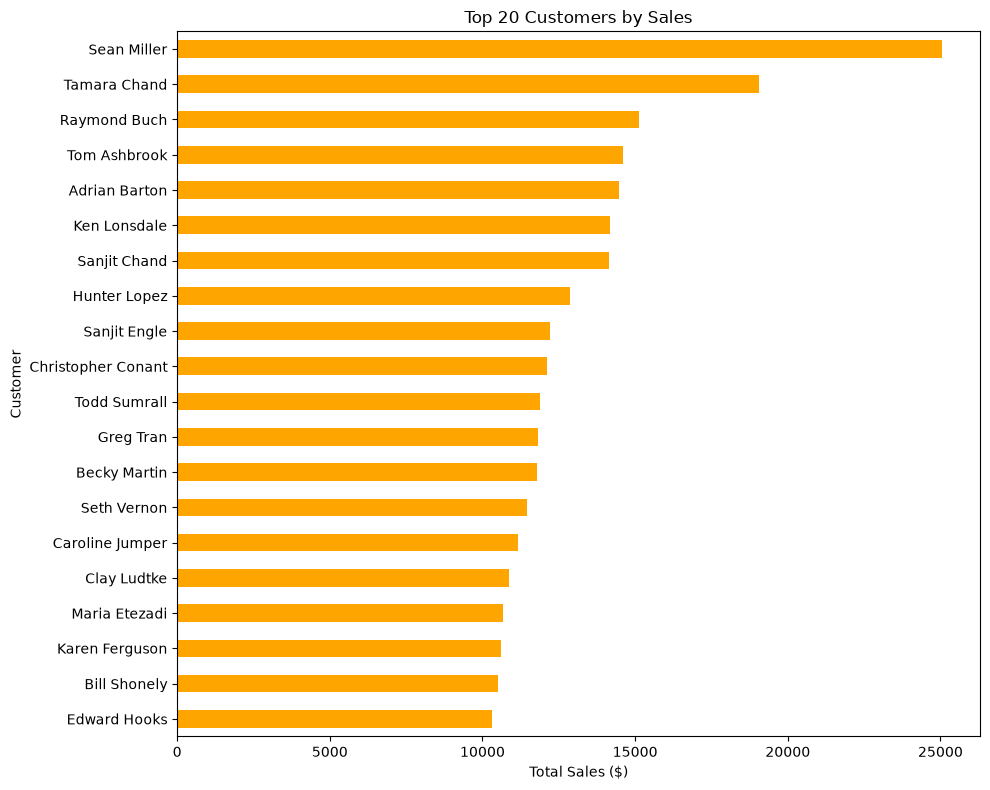

In [166]:
ax = top_20_sales.set_index("customer_name")["sum_sales"].plot(
    kind="barh",
    figsize=(10, 8),
    color="orange"
)

ax.invert_yaxis()
ax.set_title("Top 20 Customers by Sales")
ax.set_xlabel("Total Sales ($)")
ax.set_ylabel("Customer")

plt.tight_layout()
plt.show()

Conclusion: Sean Miller has the highest total sales among all customers, with approximately $25,000, followed by Tamara Chand with around $19,000. The remaining customers in the top 20 have noticeably lower sales.

### 8. Plot the Cumulative curve in Sales by Customers. Can we apply Pareto principle to customers and Sales ?


In [173]:
df_customers_sales = df_customers.sort_values("sum_sales", ascending=False)

display(df_customers_sales)

,customer_name,sum_profit,sum_sales,customer_number,customer_share
Customer ID,,,,,
SM-20320,Sean Miller,-1980.7393,25043.050,786,0.991173
TC-20980,Tamara Chand,8981.3239,19052.218,1,0.001261
RB-19360,Raymond Buch,6976.0959,15117.339,2,0.002522
TA-21385,Tom Ashbrook,4703.7883,14595.620,6,0.007566
AB-10105,Adrian Barton,5444.8055,14473.571,5,0.006305
...,...,...,...,...,...
RS-19870,Roy Skaria,9.5838,22.328,629,0.793190
MG-18205,Mitch Gastineau,-1.2453,16.739,641,0.808323
CJ-11875,Carl Jackson,1.6520,16.520,634,0.799496


In [172]:
top_20_sales_customers = df_customers_sales.head(top_20_count)

pareto_sales = (
    top_20_sales_customers["sum_sales"].sum()
    / df_customers_sales["sum_sales"].sum()
)

display(pareto_sales)

np.float64(0.48148350682558727)

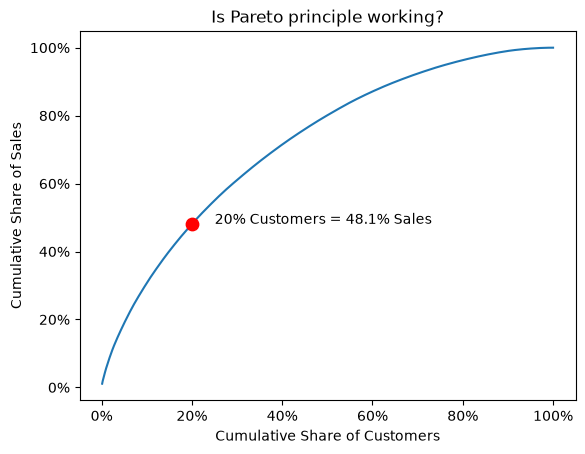

In [175]:
cumulative_sales_share=df_customers_sales["sum_sales"].cumsum()/df_customers_sales["sum_sales"].sum()
df_customers_sales["customer_number"]=range(1,len(df_customers_sales)+1)
df_customers_sales["customer_share"]=df_customers_sales["customer_number"]/len(df_customers_sales)

plt.plot(df_customers_sales["customer_share"], cumulative_sales_share)
plt.title("Is Pareto principle working?")
plt.xlabel("Cumulative Share of Customers")
plt.ylabel("Cumulative Share of Sales")

from matplotlib.ticker import PercentFormatter

ax = plt.gca()

ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

x_20=top_20_count/len(df_customers_sales)
y_20=pareto_sales

plt.scatter(x_20,y_20,color="red",s=80,zorder=5)
plt.text(x_20 + 0.05, y_20, f"20% Customers = {y_20:.1%} Sales")

plt.show()


Conclusion: The top 20% of customers generate approximately 48.15% of total sales. This means the Pareto Principle does not apply to Sales, unlike Profit, where the top 20% contribute around 81.66%.

### 9. Based on the analysis, make decisions on which states and cities to prioritize for marketing strategies.


Based on the analysis, I would prioritize New York, California and Washington for future marketing strategies.

New York looks especially promising because it generates almost the same profit as California with much lower sales. New York City also has the highest sales and profit among all cities.

Los Angeles, San Francisco and Seattle are also good options because of their strong performance.

I would be more careful with marketing investments in states like Texas, Ohio, Illinois and Pennsylvania, where profit margins are negative. The company should investigate the reasons for these losses before increasing spending.

Finally, since the top 20% of customers generate around 81.7% of total profit, keeping these valuable customers should be an important part of the marketing strategy.